<a href="https://colab.research.google.com/github/JosefinaMenta/Aprendizaje-Autom-tico-2026/blob/main/Clase%206/notebook/Libros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Éxito de Libros en Google Books

Se desarrollan dos modelos de Aprendizaje Automático para predecir si un libro puede ser considerado **"exitoso"** (definido como un rating promedio de 4.0 o superior) en función de sus características principales. Se comparan Rregresión Logística y Árbol de decisión.

Se utiliza un dataset extraído de kaggle, de Google Books que combina variables numéricas y categóricas:
* **Variables predictoras:** `page_count`, `ratings_count`, `publisher`, `language` y `search_category`.
* **Variable objetivo (`es_exitoso`):** Variable binaria (1 si es exitoso, 0 en caso contrario).



In [76]:
import pandas as pd
import numpy as np

df = pd.read_csv('google_books_dataset.csv')

print("--- ESTRUCTURA DEL DATASET ---")
df.info()

print("\n--- VALORES FALTANTES O NULOS ---")
print(df.isnull().sum())

--- ESTRUCTURA DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15147 entries, 0 to 15146
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   book_id          15147 non-null  object 
 1   title            15139 non-null  object 
 2   subtitle         5983 non-null   object 
 3   authors          11622 non-null  object 
 4   publisher        7090 non-null   object 
 5   published_date   14933 non-null  object 
 6   description      8351 non-null   object 
 7   page_count       14933 non-null  float64
 8   categories       12695 non-null  object 
 9   average_rating   857 non-null    float64
 10  ratings_count    15147 non-null  int64  
 11  language         15147 non-null  object 
 12  preview_link     15147 non-null  object 
 13  info_link        15147 non-null  object 
 14  isbn_13          7383 non-null   float64
 15  isbn_10          7121 non-null   object 
 16  list_price       2943 non-n

In [77]:
# nos quedamos primero solo con los libros que tienen rating (nuestra base para el target)
df_filtrado = df.dropna(subset=['average_rating']).copy()

# creamos la variable objetivo (Target): 1 si el rating es >= 4.0, 0 en caso contrario
df_filtrado['es_exitoso'] = (df_filtrado['average_rating'] >= 4.0).astype(int)

# seleccionamos únicamente las columnas que nos interesan (las 5 predictoras + el target)
columnas_utiles = [
    'page_count',
    'ratings_count',
    'publisher',
    'language',
    'search_category',
    'es_exitoso'
]

#eliminamos filas que tengan valores nulos SOLO en estas columnas y vemos el total
df_modelo = df_filtrado[columnas_utiles].dropna().copy()

print(f"Número total de observaciones listas para entrenar: {len(df_modelo)}")
print("\n--- DISTRIBUCIÓN DE CLASES ---")
print(df_modelo['es_exitoso'].value_counts())

Número total de observaciones listas para entrenar: 710

--- DISTRIBUCIÓN DE CLASES ---
es_exitoso
1    528
0    182
Name: count, dtype: int64


In [78]:
# separamos nuestras variables predictoras (X) de nuestra variable objetivo (y)
X = df_modelo[['page_count', 'ratings_count', 'publisher', 'language', 'search_category']]
y = df_modelo['es_exitoso']

# aplicamos One-Hot Encoding a todo el dataframe de predictoras
# el parámetro drop_first=True es una buena práctica para evitar la multicolinealidad
X_encoded = pd.get_dummies(X, drop_first=True)

print(f"Número original de columnas predictoras: {X.shape[1]}")
print(f"Número de columnas predictoras tras el One-Hot Encoding: {X_encoded.shape[1]}")

# primeras columnas resultantes para comprobar
X_encoded.head(3)

Número original de columnas predictoras: 5
Número de columnas predictoras tras el One-Hot Encoding: 419


,page_count,ratings_count,publisher_A&C Black,publisher_ACTEX Publications,publisher_AGUILAR,publisher_Addison Wesley Publishing Company,publisher_Addison-Wesley,publisher_Addison-Wesley Professional,publisher_Aguilar,publisher_Algonquin Books,...,search_category_year_2011,search_category_year_2013,search_category_year_2017,search_category_year_2018,search_category_year_2020,search_category_year_2021,search_category_year_2023,search_category_yoga practice,search_category_young adult fantasy,search_category_young adult romance
130,193.0,1,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
142,288.0,1,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
151,767.0,1,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamaño del conjunto de entrenamiento (X_train): {X_train.shape[0]} registros")
print(f"Tamaño del conjunto de prueba (X_test): {X_test.shape[0]} registros")

Tamaño del conjunto de entrenamiento (X_train): 568 registros
Tamaño del conjunto de prueba (X_test): 142 registros


Accuracy (Exactitud): 0.5845

--- MATRIZ DE CONFUSIÓN (TEXTO) ---
[[16 20]
 [39 67]]

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       0.29      0.44      0.35        36
           1       0.77      0.63      0.69       106

    accuracy                           0.58       142
   macro avg       0.53      0.54      0.52       142
weighted avg       0.65      0.58      0.61       142



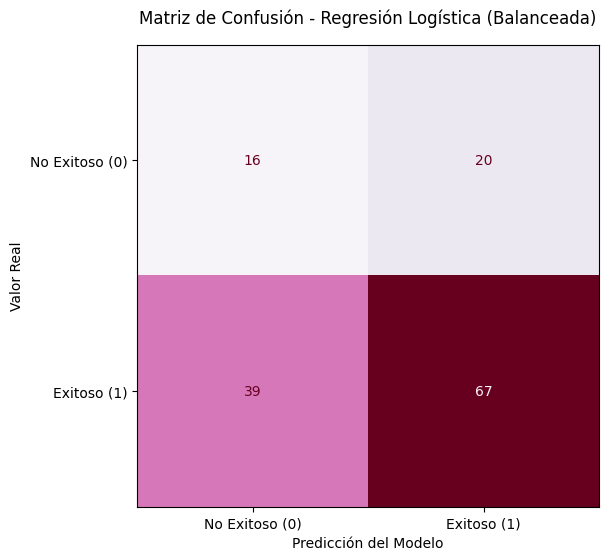

In [80]:
# regresión logística con class_weight='balanced'
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Agregamos class_weight='balanced' para compensar el sesgo de las clases
modelo_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train, y_train)

y_pred_lr = modelo_lr.predict(X_test)

# métricas
print(f"Accuracy (Exactitud): {accuracy_score(y_test, y_pred_lr):.4f}\n")
print("--- MATRIZ DE CONFUSIÓN (TEXTO) ---")
print(confusion_matrix(y_test, y_pred_lr))
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred_lr))

# Matriz de Confusión en tonos rosas ('PuRd')
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    modelo_lr,
    X_test,
    y_test,
    cmap='PuRd',
    display_labels=['No Exitoso (0)', 'Exitoso (1)'],
    ax=ax,
    colorbar=False
)
plt.title('Matriz de Confusión - Regresión Logística (Balanceada)', fontsize=12, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=10)
plt.ylabel('Valor Real', fontsize=10)
plt.grid(False)
plt.show()

Con esta configuración, el modelo alcanza una exactitud global del 58.5%. El aspecto más destacable del balanceo es que permite al algoritmo prestar atención a los libros no exitosos (Clase 0), logrando un recall del 44.0% (detectando 16 de 36 casos), lo que genera un perfil de predicción mucho más equitativo entre ambas categorías en comparación con un entrenamiento estándar.

Accuracy (Exactitud) - Árbol de Decisión: 0.6268

--- MATRIZ DE CONFUSIÓN (TEXTO) ---
[[ 7 29]
 [24 82]]

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       0.23      0.19      0.21        36
           1       0.74      0.77      0.76       106

    accuracy                           0.63       142
   macro avg       0.48      0.48      0.48       142
weighted avg       0.61      0.63      0.62       142



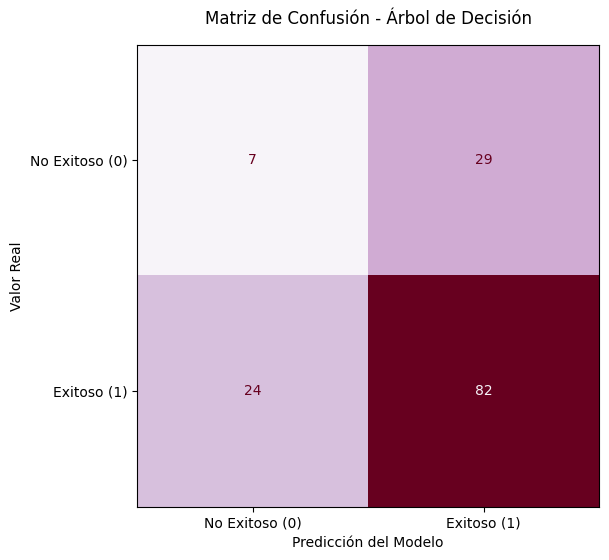

In [81]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# mantenemos el árbol estándar
modelo_tree = DecisionTreeClassifier(random_state=42)
modelo_tree.fit(X_train, y_train)

y_pred_tree = modelo_tree.predict(X_test)

print(f"Accuracy (Exactitud) - Árbol de Decisión: {accuracy_score(y_test, y_pred_tree):.4f}\n")
print("--- MATRIZ DE CONFUSIÓN (TEXTO) ---")
print(confusion_matrix(y_test, y_pred_tree))
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred_tree))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    modelo_tree, X_test, y_test,
    cmap='PuRd', display_labels=['No Exitoso (0)', 'Exitoso (1)'],
    ax=ax, colorbar=False
)
plt.title('Matriz de Confusión - Árbol de Decisión', fontsize=12, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=10)
plt.ylabel('Valor Real', fontsize=10)
plt.grid(False)
plt.show()

El Árbol de Decisión estándar alcanza una exactitud global del 62.7% y muestra un desempeño sólido al identificar la categoría mayoritaria con un recall del 77.0% en los libros exitosos. Sin embargo, al igual que los modelos no balanceados, evidencia dificultades notables para detectar la categoría minoritaria (libros no exitosos), obteniendo un recall de apenas el 19.0% (detectando solo 7 de 36 casos).

In [82]:
resultados_comparativos = {
    "Métrica": [
        "Accuracy (Exactitud Global)",
        "Precision (Clase 0 - No Exitoso)",
        "Recall (Clase 0 - No Exitoso)",
        "Precision (Clase 1 - Exitoso)",
        "Recall (Clase 1 - Exitoso)"
    ],
    "Regresión Logística (Balanceada)": [0.5845, 0.29, 0.44, 0.77, 0.63],
    "Árbol de Decisión (Estándar)": [0.6268, 0.23, 0.19, 0.74, 0.77]
}

df_comparacion = pd.DataFrame(resultados_comparativos)

df_comparacion.style.format({
    "Regresión Logística (Balanceada)": "{:.1%}",
    "Árbol de Decisión (Estándar)": "{:.1%}"
})

,Métrica,Regresión Logística (Balanceada),Árbol de Decisión (Estándar)
0,Accuracy (Exactitud Global),58.5%,62.7%
1,Precision (Clase 0 - No Exitoso),29.0%,23.0%
2,Recall (Clase 0 - No Exitoso),44.0%,19.0%
3,Precision (Clase 1 - Exitoso),77.0%,74.0%
4,Recall (Clase 1 - Exitoso),63.0%,77.0%


Al comparar ambos modelos, se evidencia una diferencia clara en su enfoque de clasificación. El Árbol de Decisión estándar alcanza una exactitud global ligeramente superior (62.7%) y muestra un rendimiento sólido al identificar los libros exitosos, aunque tiene dificultades para detectar la categoría minoritaria. Por el contrario, la Regresión Logística con balanceo de clases reduce su exactitud general (58.5%) para compensar el desequilibrio del dataset, logrando duplicar la capacidad de detección de los libros no exitosos y ofreciendo un perfil de predicción más equilibrado entre ambas categorías.